In [3]:
import statsmodels.api as sm
import numpy as np
import pandas as pd

In [4]:
# MAIN PARAMETERS
ACTIVE_MODEL = "linear_regression"

# linear_regression, xgboost

NUMERIC_SKEWED_FEATURES = [
    "sales_lag15",
    "sales_lag21",
    "sales_lag364",
    # "sales_lag365",
]
NUMERIC_NORMAL_FEATURES = []

TIER_FEATURES = []
CATEGORICAL_FEATURES = []
TARGET_ENCODER = False

TARGET = "sales"

COLUMNS_TO_KEEP = ["date", "family", "store_nbr", "is_int_sales"]

CUTOFFS_STR = ["2017-07-15", "2017-04-15", "2017-01-15", "2016-09-15"]
CUTOFFS_DATETIME = pd.to_datetime(CUTOFFS_STR)

HORIZON = 15

ISSUE_NAME = "lags"
VERSION_NAME = "[15-21]+30,60,364,365"

PATH_TRAIN_DF = "../data/processed/df_train.parquet"

In [5]:
df = pd.read_parquet(PATH_TRAIN_DF)

cutoff_date = max(CUTOFFS_STR)
df_train = df[df["date"] <= cutoff_date].copy()

y_train_eda = np.log1p(df_train["sales"])
X_train_eda = df_train[NUMERIC_SKEWED_FEATURES].copy()

for col in NUMERIC_SKEWED_FEATURES:
    X_train_eda[col] = np.log1p(X_train_eda[col])

X_train_sm = sm.add_constant(X_train_eda)
model_sm = sm.OLS(y_train_eda, X_train_sm).fit()

print(model_sm.summary2())

                   Results: Ordinary least squares
Model:              OLS              Adj. R-squared:     0.896       
Dependent Variable: sales            AIC:                5882769.9138
Date:               2026-11-16 14:19 BIC:                5882820.5243
No. Observations:   2309736          Log-Likelihood:     -2.9414e+06 
Df Model:           3                F-statistic:        6.604e+06   
Df Residuals:       2309732          Prob (F-statistic): 0.00        
R-squared:          0.896            Scale:              0.74756     
-----------------------------------------------------------------------
                Coef.    Std.Err.      t       P>|t|    [0.025   0.975]
-----------------------------------------------------------------------
const           0.1594     0.0009   181.7223   0.0000   0.1577   0.1611
sales_lag15     0.4328     0.0007   652.3224   0.0000   0.4315   0.4341
sales_lag21     0.4025     0.0007   582.6898   0.0000   0.4011   0.4038
sales_lag364    0.1353     

In [6]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data["Variable"] = X_train_sm.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_train_sm.values, i) for i in range(X_train_sm.shape[1])
]

print(vif_data.sort_values("VIF", ascending=False))

       Variable        VIF
2   sales_lag21  10.597109
1   sales_lag15   9.763038
3  sales_lag364   4.106521
0         const   1.000000


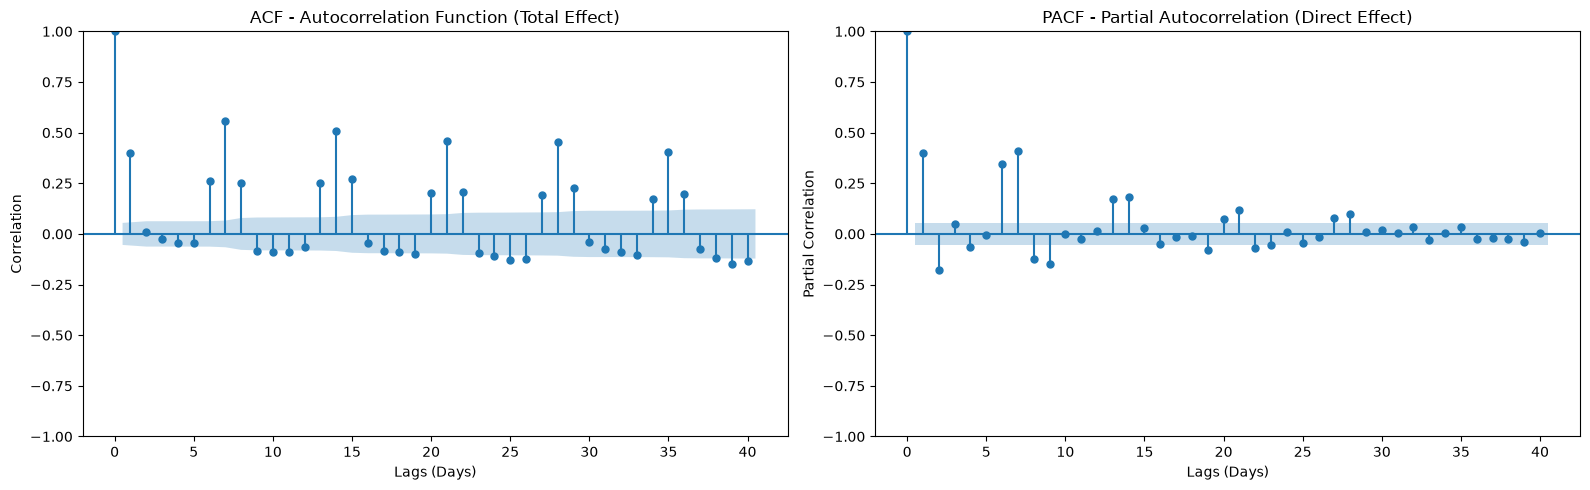

In [ ]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

single_series = df_train[
    (df_train["store_nbr"] == 44) & (df_train["family"] == "GROCERY I")
].set_index("date")["sales"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

plot_acf(single_series, lags=40, ax=axes[0], alpha=0.05)
axes[0].set_title("ACF - Autocorrelation Function (Total Effect)")
axes[0].set_xlabel("Lags (Days)")
axes[0].set_ylabel("Correlation")

plot_pacf(single_series, lags=40, ax=axes[1], alpha=0.05)
axes[1].set_title("PACF - Partial Autocorrelation (Direct Effect)")
axes[1].set_xlabel("Lags (Days)")
axes[1].set_ylabel("Partial Correlation")

plt.tight_layout()
plt.show()